<img src="img/logoitqv1.jpg" alt="Instituto Superior Tecnológico Quito" width="500">
<br>

# Implementando la Neurona M-P

## Caso Práctico: Neurona de McCulloch y Pitts
<br>

<img src="img/python_logo.png" alt="Python" width="300">
<br>

*Jesús Viera* https://github.com/Vierita23/Practica-2

### 1. Implementación de la MPNeuron

In [1]:
import numpy as np  # sirve para devolver las respuestas como array, no como lista

class MPNeuron:
    def __init__(self):
        self.threshold = None  # umbral: cuantos 1 hacen falta para que la neurona responda True

    def model(self, x):
        # x es una sola muestra, por ejemplo [1, 0, 1, 0]
        z = sum(x)  # suma las entradas: como son 0 y 1, cuenta cuantos 1 hay
        return (z >= self.threshold)  # True si la suma llega al umbral, si no False

    def predict(self, X):
        # X son varias muestras juntas. Sirve para probar mas de una a la vez
        Y = []  # aqui guardo la respuesta de cada muestra
        for x in X:  # recorro una muestra por vuelta
            result = self.model(x)  # le paso esa muestra al modelo
            Y.append(result)  # guardo si dio True o False
        return np.array(Y)  # lo paso a array para verlo como array([False, True, ...])

In [2]:
# creo la neurona. Todavia no predice nada porque el umbral esta vacio
mp_neuron = MPNeuron()

In [3]:
# el umbral queda en 4: solo responde True si hay 4 unos o mas
mp_neuron.threshold = 4

In [4]:
# pruebo 3 muestras para ver como se comporta con ese umbral
# la primera suma 1, la segunda suma 4 y la tercera suma 3
mp_neuron.predict([[1, 0, 0, 0], [1, 1, 1, 1], [1, 1, 1, 0]])

array([False,  True, False])

## 2. Aplicando la MPNeuron a un caso práctico real

### 2.1. Conjunto de datos
Copia de los datos de UCI ML Breast Cancer Wisconsin (Diagnóstico): https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

### Descripción de la muestra

Las características salen de una imagen digitalizada de un aspirado de aguja fina (FNA) de una masa mamaria. Describen los núcleos de las células que se ven en esa imagen.

El plano de separación se obtuvo con un árbol de múltiples superficies (MSM-T), un árbol de decisión hecho con programación lineal. El programa lineal del plano en tres dimensiones es el que describen K. P. Bennett y O. L. Mangasarian.

### Lectura de datos

In [5]:
from sklearn.datasets import load_breast_cancer  # trae el dataset de cancer de mama

cancer_mama = load_breast_cancer()  # lo cargo. Ya viene armado dentro de sklearn
# X son las medidas de las celulas. Y es la clase: 0 maligno, 1 benigno
X = cancer_mama.data
Y = cancer_mama.target

In [6]:
dir(cancer_mama)  # lista que mas trae el dataset, ademas de data y target

['DESCR',
 'data',
 'data_module',
 'feature_names',
 'filename',
 'frame',
 'target',
 'target_names']

In [7]:
print(X)  # muestro la tabla de numeros: 569 muestras y 30 medidas cada una

[[1.799e+01 1.038e+01 1.228e+02 ... 2.654e-01 4.601e-01 1.189e-01]
 [2.057e+01 1.777e+01 1.329e+02 ... 1.860e-01 2.750e-01 8.902e-02]
 [1.969e+01 2.125e+01 1.300e+02 ... 2.430e-01 3.613e-01 8.758e-02]
 ...
 [1.660e+01 2.808e+01 1.083e+02 ... 1.418e-01 2.218e-01 7.820e-02]
 [2.060e+01 2.933e+01 1.401e+02 ... 2.650e-01 4.087e-01 1.240e-01]
 [7.760e+00 2.454e+01 4.792e+01 ... 0.000e+00 2.871e-01 7.039e-02]]


### Visualización del conjunto de datos

In [8]:
import pandas as pd  # para ver los datos como tabla con nombres

df = pd.DataFrame(X, columns=cancer_mama.feature_names)  # cada columna queda con su nombre (radius, texture, ...)
df  # lo muestro para revisar las primeras y las ultimas filas

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [9]:
print(Y)  # la clase de cada fila: 0 maligno, 1 benigno

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 1 0 1 1 1 1 1 0 0 1 0 0 1 1 1 1 0 1 0 0 1 1 1 1 0 1 0 0
 1 0 1 0 0 1 1 1 0 0 1 0 0 0 1 1 1 0 1 1 0 0 1 1 1 0 0 1 1 1 1 0 1 1 0 1 1
 1 1 1 1 1 1 0 0 0 1 0 0 1 1 1 0 0 1 0 1 0 0 1 0 0 1 1 0 1 1 0 1 1 1 1 0 1
 1 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1 0 1 1 0 0 1 1 0 0 1 1 1 1 0 1 1 0 0 0 1 0
 1 0 1 1 1 0 1 1 0 0 1 0 0 0 0 1 0 0 0 1 0 1 0 1 1 0 1 0 0 0 0 1 1 0 0 1 1
 1 0 1 1 1 1 1 0 0 1 1 0 1 1 0 0 1 0 1 1 1 1 0 1 1 1 1 1 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 1 1 1 1 1 0 1 0 1 1 0 1 1 0 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1
 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 0 1 1 1 1 0 0 0 1 1
 1 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1 0 0
 0 1 0 0 1 1 1 1 1 0 1 1 1 1 1 0 1 1 1 0 1 1 0 0 1 1 1 1 1 1 0 1 1 1 1 1 1
 1 0 1 1 1 1 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 1 0 1 1 1 1 1 0 1 1
 0 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1
 1 1 1 1 1 1 0 1 0 1 1 0 

### División del conjunto de datos

In [10]:
from sklearn.model_selection import train_test_split  # parte los datos en dos grupos

# train sirve para elegir el umbral. test se guarda para medir despues, sin haberlo usado antes
# stratify=Y deja la misma proporcion de malignos y benignos en los dos grupos
X_train, X_test, y_train, y_test = train_test_split(df, Y, stratify=Y)
print("Tamaño de entrenamiento ", len(X_train))  # cuantas filas uso para entrenar
print("Tamaño de pruebas", len(X_test))  # cuantas dejo para probar

Tamaño de entrenamiento  426
Tamaño de pruebas 143


### Implementación de una MPNeuron más avanzada

Esta neurona no solo predice. También busca el umbral que más acierta.

In [11]:
import numpy as np  # otra vez, para devolver las predicciones como array
from sklearn.metrics import accuracy_score  # mide que fraccion de filas acerto

class MpNeurona:
    # esta neurona, ademas de predecir, busca sola el mejor umbral
    def __init__(self):
        self.threshold = None  # el umbral lo va a elegir fit, no yo a mano

    def model(self, x):
        # x es una fila ya en 0 y 1
        z = sum(x)  # cuenta cuantos 1 tiene esa muestra
        return (z >= self.threshold)  # True si llega al umbral

    def predict(self, X):
        # aplica model a cada fila y junta las respuestas
        Y = []
        for x in X:
            result = self.model(x)  # respuesta de esa fila
            Y.append(result)
        return np.array(Y)

    def fit(self, X, Y):
        # prueba todos los umbrales posibles y se queda con el que mas acierta
        accuracy = {}  # umbral -> que tan bien le fue
        # de 0 hasta el numero de columnas. Con 30 medidas, prueba 0, 1, 2, ... 30
        for th in range(X.shape[1] + 1):
            self.threshold = th  # pruebo este umbral
            Y_pred = self.predict(X)  # prediccion del train con ese umbral
            accuracy[th] = accuracy_score(Y_pred, Y)  # fraccion de aciertos
        # max con key=accuracy.get devuelve el umbral cuyo acierto fue el mas alto
        self.threshold = max(accuracy, key=accuracy.get)

Los datos siguen siendo un problema: las columnas traen números continuos y esta neurona solo suma 0 y 1. Hay que pasar cada columna a binario.

[0, 0, 1, 1, 1, 0, 0]
Categories (2, int64): [0 < 1]


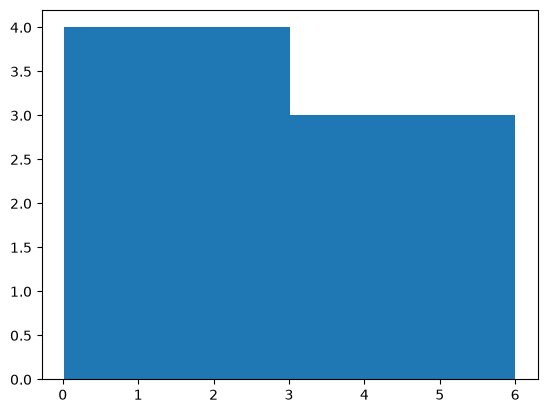

In [12]:
# ejemplo chico para ver como pd.cut parte numeros en dos grupos: 0 y 1
import matplotlib.pyplot as plt  # para el histograma

print(pd.cut([0.04, 0.3, 4, 5, 6, 0.02, 0.6], bins=2, labels=[0, 1]))  # los chicos quedan 0, los grandes 1
plt.hist([0.04, 0.3, 4, 5, 6, 0.02, 0.6], bins=2)  # las dos barras: grupo bajo y grupo alto
plt.show()

In [13]:
# la neurona solo suma 0 y 1, y estas columnas son numeros continuos
# pd.cut parte cada columna en 2. labels=[1, 0]: el tramo bajo pasa a 1 y el alto a 0
X_train_bin = X_train.apply(pd.cut, bins=2, labels=[1, 0])
X_test_bin = X_test.apply(pd.cut, bins=2, labels=[1, 0])  # el test se parte igual, pero no se usa para entrenar
X_train_bin  # lo muestro para ver que ya solo hay 0 y 1

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
201,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,0,1,1
243,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
520,1,1,1,1,0,1,1,1,0,0,...,1,1,1,1,0,1,1,1,1,1
456,1,0,1,1,1,1,1,1,1,1,...,1,0,1,1,1,1,1,1,1,1
239,1,0,1,1,1,1,1,1,1,1,...,0,0,1,1,1,1,1,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
213,1,0,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
161,0,1,0,1,1,1,1,0,1,1,...,0,1,1,1,1,1,1,0,1,1
383,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
355,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1


In [14]:
np_neurona = MpNeurona()  # neurona nueva, todavia sin umbral
# to_numpy pasa la tabla a array, que es lo que fit sabe leer
np_neurona.fit(X_train_bin.to_numpy(), y_train)  # elige el umbral mirando solo el train
np_neurona.threshold  # el umbral que mas acerto

27

In [15]:
# predigo el test. Esas filas no se usaron para elegir el umbral
Y_pred = np_neurona.predict(X_test_bin.to_numpy())
Y_pred  # True o False de cada paciente de prueba

array([False,  True,  True,  True,  True,  True,  True, False,  True,
       False, False,  True,  True,  True, False,  True,  True,  True,
        True,  True,  True,  True,  True,  True, False, False,  True,
       False,  True,  True, False, False, False,  True, False, False,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True, False,  True,  True,  True,  True,  True, False,  True,
       False,  True,  True,  True,  True,  True,  True,  True, False,
        True,  True, False,  True,  True,  True, False,  True, False,
        True,  True, False,  True,  True, False, False,  True, False,
       False, False, False, False,  True, False, False,  True, False,
       False, False,  True,  True,  True,  True,  True,  True,  True,
       False,  True,  True, False,  True,  True, False, False,  True,
        True,  True,  True,  True, False,  True,  True, False,  True,
       False,  True,  True, False, False,  True, False,  True, False,
       False,  True,

In [16]:
# accuracy_score compara la clase real (y_test) con lo que predijo
# el resultado es la fraccion de pacientes de prueba que acerto. 1 seria todos
accuracy_score(y_test, Y_pred)

0.8741258741258742